Saving processes_datasets.csv to processes_datasets (1).csv

**************************
*   Data Preprocessing   *
**************************

Loaded 404,176 rows from processes_datasets (1).csv
Valid records after cleaning: 339,314
Selected 4,000 earliest valid jobs.
Training jobs: 3,200
Testing jobs: 800

***************************
*   Experiment Settings   *
***************************

Test size: 20%
NN batch size: 64
NN epochs: 25
RF trees: 100

Input attributes: ['SubmitTime', 'UserID', 'ReqTime', 'ReqMemory']
Target attribute: RunTime (seconds)

Training Random Forest...
Training Support Vector Regression...
Training Neural Network...

*******************************************
*   Machine Learning Regression Results   *
*******************************************

ML Model  MAE (seconds)  RMSE (seconds)    R²  Training time (s)
      RF       3,014.75       15,115.86 -0.43               1.21
     SVR       4,377.05       12,604.08  0.00               0.78
      NN      15,651

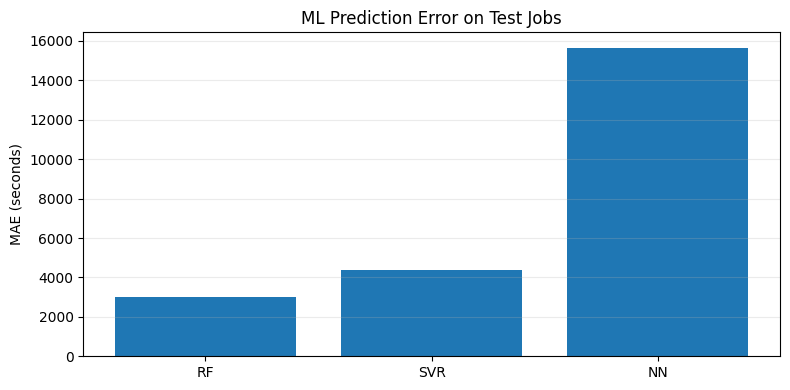

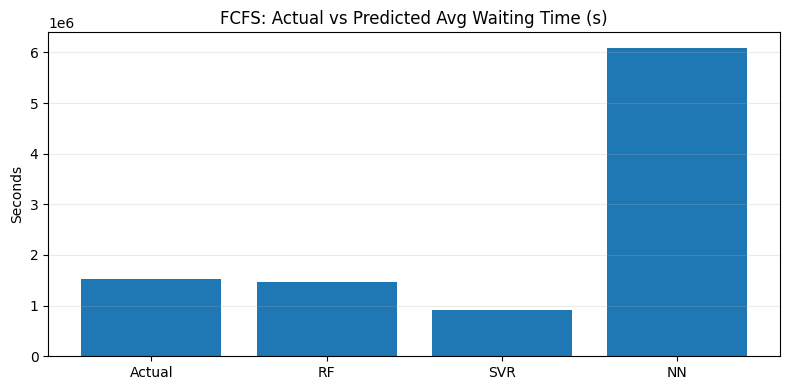

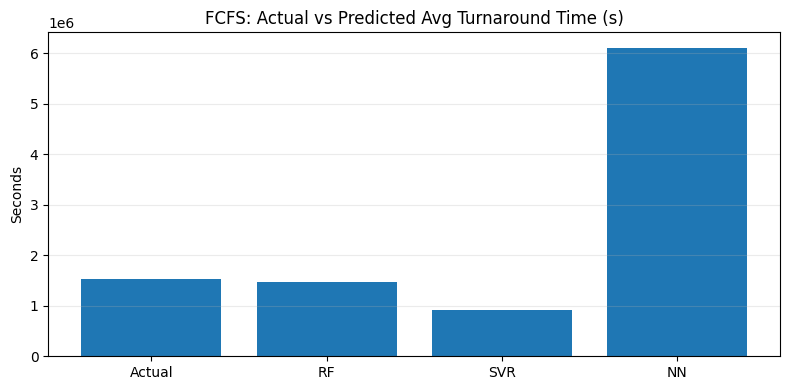

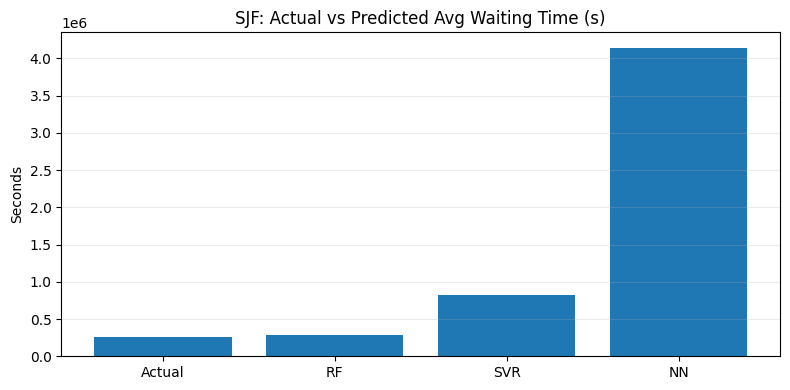

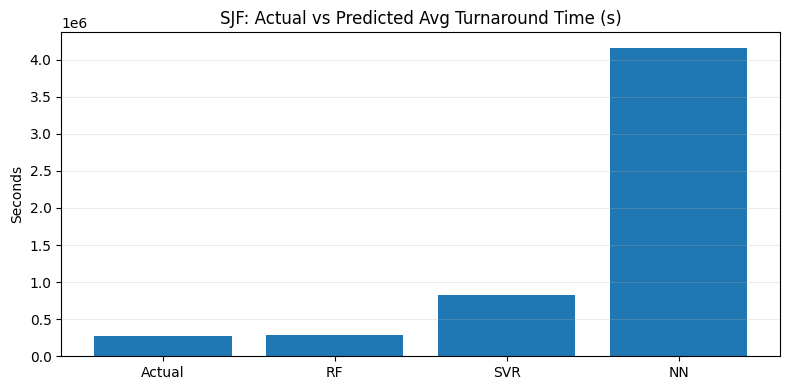


Saved results as CSV files in the notebook's working directory.


In [ ]:
# ***********************
# Import Python libraries
# ***********************

import time
import heapq
import numpy as np
import pandas as pd
pd.set_option("display.float_format", "{:,.2f}".format)
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers

# ********************************************
# Model settings
# ********************************************

NN_BATCH_SIZE = 64   # Neural network batch size
NN_EPOCHS = 25       # Neural network training epochs
RF_TREES = 100       # Number of Random Forest trees
TEST_SIZE = 0.20     # 20% test data and 80% training data

# Fixed seed for repeatable results (not a model setting).
np.random.seed(42)
keras.utils.set_random_seed(42)

# ***********************
# Loading dataset
# ***********************
def load_dataset_man():
    # Manually upload the CSV using Google Colab.
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No CSV file was uploaded.")

    print("\n**************************")
    print("*   Data Preprocessing   *")
    print("**************************\n")

    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name, low_memory=False)
    print(f"Loaded {len(df):,} rows from {file_name}")
    return df

'''
def load_dataset_auto():
    # Automatically read the CSV from your Google Drive folder.
    from google.colab import drive
    drive.mount('/content/drive')
    file_path = '/content/drive/MyDrive/Adv OS Term Project/processes_datasets.csv'
    # Change file_path above if your Google Drive folder has a different name.

    print("\n**************************")
    print("*   Data Preprocessing   *")
    print("**************************\n")

    df = pd.read_csv(file_path, low_memory=False)
    print(f"Loaded {len(df):,} rows from Google Drive")
    return df
'''

def select_columns(df):
    """Keep the proposed inputs, actual RunTime, and JobID for tracking."""
    df = df.copy()
    # Original CSV column labels contain whitespace and punctuation.
    df.columns = df.columns.str.strip()
    df = df.rename(columns={"ReqTime:": "ReqTime"})
    columns = ["JobID", "SubmitTime", "UserID", "ReqTime", "ReqMemory", "RunTime"]
    missing = [col for col in columns if col not in df.columns]
    if missing:
        raise ValueError(f"Dataset is missing expected columns: {missing}")
    return df[columns].copy()

# *************************************
# Cleaning invalid / missing job values
# *************************************
def clean_dataset(df):
    """Keep jobs with usable arrival times and strictly positive actual runtimes.

    -1 is a missing-value sentinel for some fields in this workload.
    Missing predictors are imputed later using TRAINING data only.
    """
    df = df.copy()
    numeric = ["JobID", "SubmitTime", "RunTime", "ReqTime", "ReqMemory"]
    for col in numeric:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    for col in ["ReqTime", "ReqMemory"]:
        df.loc[df[col] < 0, col] = np.nan
    df["UserID"] = df["UserID"].replace({"-1": np.nan, "": np.nan})
    df = df.dropna(subset=["JobID", "SubmitTime", "RunTime"])
    df = df[(df["RunTime"] > 0) & (df["SubmitTime"] >= 0)]
    df = df.drop_duplicates(subset="JobID", keep="first")
    df = df.sort_values(["SubmitTime", "JobID"], kind="stable").reset_index(drop=True)
    print(f"Valid records after cleaning: {len(df):,}")
    return df

# **********************************************
# Select a configurable number of valid records
# **********************************************
def select_number_of_jobs(df, number_of_jobs):
    """Select earliest N valid jobs; never sample after seeing model performance."""
    if not isinstance(number_of_jobs, int) or number_of_jobs < 10:
        raise ValueError("NUMBER_OF_JOBS must be an integer of at least 10.")
    if number_of_jobs > len(df):
        raise ValueError(f"Requested {number_of_jobs:,} jobs, but only {len(df):,} valid jobs exist.")
    selected = df.iloc[:number_of_jobs].copy().reset_index(drop=True)
    print(f"Selected {len(selected):,} earliest valid jobs.")
    return selected


# *********************************
# Define input features and target
# *********************************
def define_features_target(df):
    feature_cols = ["SubmitTime", "UserID", "ReqTime", "ReqMemory"]
    X = df[feature_cols].copy()
    y = df["RunTime"].astype(float).copy()
    return X, y

# ****************************
# Identify feature types
# ****************************
def identify_feature_types(X):
    numeric_features = [c for c in X.columns if c != "UserID"]
    categorical_features = ["UserID"]
    return numeric_features, categorical_features

# ****************************
# Preprocessing
# ****************************
def build_preprocessor(numeric_features, categorical_features):
    """Training-only imputation, scaling, and categorical encoding.

    UserID is categorical, NOT an ordered number. Unknown users in the test set
    are safely ignored by OneHotEncoder(handle_unknown='ignore').
    """
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", num_pipe, numeric_features),
        ("categorical", cat_pipe, categorical_features),
    ], remainder="drop")

# ****************************
# Train/test split
# ****************************
def split_data(df, test_size_value):
    """Chronological 80/20 split. Preserve the matching job rows for simulations."""
    if not 0 < test_size_value < 1:
        raise ValueError("TEST_SIZE must be between 0 and 1.")
    split_at = int(len(df) * (1 - test_size_value))
    if split_at == 0 or split_at == len(df):
        raise ValueError("Not enough jobs for the requested split.")
    train_df = df.iloc[:split_at].copy().reset_index(drop=True)
    test_df = df.iloc[split_at:].copy().reset_index(drop=True)
    X_train, y_train = define_features_target(train_df)
    X_test, y_test = define_features_target(test_df)
    #print(f"Training jobs: {len(train_df):,} | Testing/simulation jobs: {len(test_df):,}")
    print(f"Training jobs: {len(train_df):,}")
    print(f"Testing jobs: {len(test_df):,}")
    #print("Train/test JobID overlap:", len(set(train_df.JobID) & set(test_df.JobID)))
    return train_df, test_df, X_train, X_test, y_train, y_test


# ****************************
# Random Forest regression
# ****************************
def run_random_forest(preprocessor, X_train, X_test, y_train):
    """Train RF and return predicted test runtimes and training time."""
    model = Pipeline([
        ("preprocess", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=RF_TREES, random_state=42, n_jobs=-1,
            min_samples_leaf=2
        )),
    ])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start
    predictions = np.maximum(model.predict(X_test), 0.001)
    return model, predictions, training_time

# **********************************
# Support Vector Regression (SVR)
# **********************************
def run_support_vector_regression(preprocessor, X_train, X_test, y_train):
    """SVR uses scaled numeric and one-hot encoded categorical predictors."""
    model = Pipeline([
        ("preprocess", preprocessor),
        ("regressor", SVR(kernel="rbf", C=10.0, epsilon=0.1)),
    ])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start
    predictions = np.maximum(model.predict(X_test), 0.001)
    return model, predictions, training_time

# ****************************
# Neural Network regression
# ****************************
def run_neural_network(preprocessor, X_train, X_test, y_train):
    """Keras regression NN; linear output predicts continuous runtime in seconds.

    The target is standardized using training-set statistics to make learning
    easier when runtimes vary by orders of magnitude. Predictions are then
    converted back to the dataset's original runtime units (seconds).
    """
    import copy
    transform = copy.deepcopy(preprocessor)
    start = time.perf_counter()
    X_train_nn = transform.fit_transform(X_train).astype("float32")
    X_test_nn = transform.transform(X_test).astype("float32")
    y_mean = float(y_train.mean())
    y_std = float(y_train.std()) or 1.0
    y_scaled = ((y_train.to_numpy() - y_mean) / y_std).astype("float32")
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        layers.Input(shape=(X_train_nn.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="linear"),  # regression, NOT sigmoid classification
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mae")
    callbacks = [keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )]
    history = model.fit(
        X_train_nn, y_scaled,
        validation_split=0.15, epochs=NN_EPOCHS,
        batch_size=NN_BATCH_SIZE, callbacks=callbacks, verbose=0,
        shuffle=False
    )
    training_time = time.perf_counter() - start
    scaled_preds = model.predict(X_test_nn, verbose=0).reshape(-1)
    predictions = np.maximum(scaled_preds * y_std + y_mean, 0.001)
    return (model, transform, history), predictions, training_time

# ****************************
# Evaluate prediction accuracy
# ****************************
def evaluate_ml_models(y_test, predictions, training_times):
    """Compare prediction errors on identical unseen jobs."""
    rows = []
    for name, pred in predictions.items():
        rows.append({
            "ML Model": name,
            "MAE (seconds)": mean_absolute_error(y_test, pred),
            "RMSE (seconds)": np.sqrt(mean_squared_error(y_test, pred)),
            "R²": r2_score(y_test, pred),
            "Training time (s)": training_times[name],
        })
    return pd.DataFrame(rows).sort_values("MAE (seconds)").reset_index(drop=True)


# *****************************************
# FCFS and non-preemptive SJF CPU scheduler
# *****************************************
def simulate_scheduler(test_df, policy, predicted_runtimes=None):
    """Simulate non-preemptive FCFS or SJF with the supplied burst times.

    Actual scenario: use dataset RunTime for scheduling and execution.
    Predicted scenario: use ML-predicted RunTime for scheduling and execution.
    Predicted scheduling times are estimates, not actual speed improvements.
    """
    df = test_df.reset_index(drop=True)
    actual = df["RunTime"].to_numpy(dtype=float)
    arrivals = df["SubmitTime"].to_numpy(dtype=float)
    job_ids = df["JobID"].to_numpy()
    estimates = (actual.copy() if predicted_runtimes is None
                 else np.asarray(predicted_runtimes, dtype=float))
    if policy not in ("FCFS", "SJF"):
        raise ValueError("policy must be 'FCFS' or 'SJF'.")
    if len(df) == 0 or len(estimates) != len(df):
        raise ValueError("Test jobs and burst times must be nonempty and have matching lengths.")
    if not np.isfinite(estimates).all() or (estimates <= 0).any():
        raise ValueError("Every predicted burst time must be finite and positive.")

    durations = estimates
    order = np.lexsort((job_ids, arrivals))
    ready = []
    next_arrival = 0
    completed = 0
    now = float(arrivals[order[0]])
    records = []

    while completed < len(df):
        # Place every process that has already arrived in the ready queue.
        while next_arrival < len(df) and arrivals[order[next_arrival]] <= now:
            i = int(order[next_arrival])
            priority = arrivals[i] if policy == "FCFS" else estimates[i]
            heapq.heappush(ready, (float(priority), float(arrivals[i]), int(job_ids[i]), i))
            next_arrival += 1

        if not ready:
            now = float(arrivals[order[next_arrival]])
            continue

        _, _, _, i = heapq.heappop(ready)
        start = now
        finish = start + durations[i]
        records.append({
            "JobID": job_ids[i],
            "Arrival": arrivals[i],
            "Actual RunTime": actual[i],
            "Predicted/Selected RunTime": estimates[i],
            "Simulated Duration": durations[i],
            "Start": start,
            "Finish": finish,
            "Waiting Time": start - arrivals[i],
            "Turnaround Time": finish - arrivals[i],
        })
        now = finish
        completed += 1

    return pd.DataFrame(records)


# ***********************************************
# Actual vs predicted: eight primary simulations
# ***********************************************
def evaluate_schedulers(test_df, predictions):
    """Compare two schedulers with actual and RF/NN/SVR burst times."""
    simulations = {}
    rows = []
    for policy in ["FCFS", "SJF"]:
        for model_name, runtimes in [("Actual", None)] + list(predictions.items()):
            label = f"{policy} - {model_name}"
            details = simulate_scheduler(test_df, policy, runtimes)
            simulations[label] = details
            rows.append({
                "Scheduler": policy,
                "Burst Times": model_name,
                "Jobs": len(details),
                "Avg Waiting Time (s)": details["Waiting Time"].mean(),
                "Avg Turnaround Time (s)": details["Turnaround Time"].mean(),
            })

    results = pd.DataFrame(rows)
    return results, simulations


# ****************************
# Model and scheduler graphs
# ****************************
def plot_results(ml_results, scheduler_results):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(ml_results["ML Model"], ml_results["MAE (seconds)"])
    ax.set(title="ML Prediction Error on Test Jobs", ylabel="MAE (seconds)")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Compare actual and predicted results within each scheduling algorithm.
    for policy in ["FCFS", "SJF"]:
        subset = scheduler_results[scheduler_results["Scheduler"] == policy]
        for metric in ["Avg Waiting Time (s)", "Avg Turnaround Time (s)"]:
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.bar(subset["Burst Times"], subset[metric])
            ax.set(title=f"{policy}: Actual vs Predicted {metric}", ylabel="Seconds")
            ax.grid(axis="y", alpha=0.25)
            plt.tight_layout()
            plt.show()


# ****************************
# Main method
# ****************************
def main():

    # Change these settings for your experiment.
    number_of_jobs = 4000   # Total jobs BEFORE splitting (2000 train / 500 test)

    # Uncomment ONE of the two dataset loading options below.
    # Manual upload from your computer:
    raw_df = load_dataset_man()

    # Automatic loading from Google Drive (comment out manual line first):
    # raw_df = load_dataset_auto()
    selected_df = select_columns(raw_df)
    cleaned_df = clean_dataset(selected_df)

    # Select valid jobs BEFORE splitting.
    df = select_number_of_jobs(cleaned_df, number_of_jobs)
    train_df, test_df, X_train, X_test, y_train, y_test = split_data(df, TEST_SIZE)

    print("\n***************************")
    print("*   Experiment Settings   *")
    print("***************************\n")
    print(f"Test size: {TEST_SIZE:.0%}")
    print(f"NN batch size: {NN_BATCH_SIZE}")
    print(f"NN epochs: {NN_EPOCHS}")
    print(f"RF trees: {RF_TREES}")

    print("\nInput attributes:", list(X_train.columns))
    print("Target attribute: RunTime (seconds)")

    # 3. Build preprocessing specification; each model fits its own copy
    #    on TRAINING data only, preventing test-set preprocessing leakage.
    numeric, categorical = identify_feature_types(X_train)
    preprocessor = build_preprocessor(numeric, categorical)
    import copy

    # 4. Train the three ML regression models and predict the SAME test jobs.
    print("\nTraining Random Forest...")
    rf_model, rf_preds, rf_time = run_random_forest(
        copy.deepcopy(preprocessor), X_train, X_test, y_train)
    print("Training Support Vector Regression...")
    svr_model, svr_preds, svr_time = run_support_vector_regression(
        copy.deepcopy(preprocessor), X_train, X_test, y_train)
    print("Training Neural Network...")
    nn_bundle, nn_preds, nn_time = run_neural_network(
        copy.deepcopy(preprocessor), X_train, X_test, y_train)

    predictions = {"RF": rf_preds, "SVR": svr_preds, "NN": nn_preds}
    training_times = {"RF": rf_time, "SVR": svr_time, "NN": nn_time}

    # 5. Compare actual and predicted runtimes using MAE / RMSE / R².
    ml_results = evaluate_ml_models(y_test, predictions, training_times)
    print("\n*******************************************")
    print("*   Machine Learning Regression Results   *")
    print("*******************************************\n")
    print(ml_results.to_string(index=False))

    # 6. Attach predictions to held-out job records for easy inspection.
    prediction_table = test_df[["JobID", "SubmitTime", "RunTime"]].copy()
    for model_name, predicted in predictions.items():
        prediction_table[f"{model_name}_Predicted_RunTime"] = predicted
    if True:
        print("\n****************************************")
        print("*   Sample Test Jobs and Predictions   *")
        print("****************************************\n")
        print(prediction_table.head(10).to_string(index=False))

    # 7. Run 8 primary simulations: actual and predicted durations for FCFS/SJF.
    scheduler_results, simulations = evaluate_schedulers(test_df, predictions)
    print("\n******************************")
    print("*   CPU Scheduling Results   *")
    print("******************************\n")
    print(scheduler_results.to_string(index=False))

    # 8. Visualize both ML and OS performance metrics.
    plot_results(ml_results, scheduler_results)

    # 9. Save data for your written report (these files appear in Colab's Files).
    ml_results.to_csv("ml_results.csv", index=False)
    scheduler_results.to_csv("scheduler_results.csv", index=False)
    prediction_table.to_csv("test_job_predictions.csv", index=False)
    for name, details in simulations.items():
        safe_name = name.replace(" ", "_").replace("/", "_").replace("(", "").replace(")", "")
        details.to_csv(f"simulation_{safe_name}.csv", index=False)
    print("\nSaved results as CSV files in the notebook's working directory.")

    # Return results so you can explore them in additional notebook cells.
    return ml_results, scheduler_results, prediction_table, simulations

# ****************************
# Program start
# ****************************
if __name__ == "__main__":
    main()